# 05 · Learning from earlier tasks: TAF, ConBO and NAF

**What you will learn.** What changes when you have already optimized *related* functions before, and how three meta/transfer BO methods in OpenBO use that experience: **TAF** (transfer acquisition function), **ConBO** (continual BO) and **NAF** (a neural acquisition function trained with reinforcement learning).

**The setting.** Ordinary BO (notebooks 01 to 04) treats every task as a stranger: it needs a few random evaluations before it knows anything. But in practice tasks come in families. Think of tuning the same device for a new person, or the same model on a new dataset: the new task resembles the old ones. If the optimum of an old task was near some point, the optimum of the new task is probably near it too. Meta-BO methods exploit that.

| method | what is reused | how |
|---|---|---|
| **TAF** (Wistuba et al.) | a GP per earlier task | the new acquisition function mixes the new task's EI with how much each *old* GP expects to improve at `x`, weighted by how relevant that old task seems |
| **ConBO** (Liao et al., CHI 2025) | one Bayesian neural net trained on all earlier users | its prediction acts as a prior for the new user; the acquisition function hands over from that prior to the user's own GP after a few steps; the users arrive in a sequence and the net keeps learning |
| **NAF** (Volpp et al., ICLR 2020, "MetaBO") | the *acquisition function itself* | a neural network maps `(μ, σ, x, t, T)` to a score and is trained, by reinforcement learning (PPO) on many tasks of the family, to pick good points |

**The task family used here.** Branin (notebook 01) with the input shifted and the output scaled by random amounts: every variant has the same shape but its optimum sits somewhere else, with a different height. An optimizer that learns *where the optima of this family tend to be* has a head start.

**What runs here, and what does not.** TAF runs live. ConBO needs about 20 minutes per seed, and NAF needs hours of training, so for those two we use the results archived in `benchmark_results/` (and run the trained NAF live, which is fast). All results are small experiments from a single training run; read them as illustrations.

In [1]:
import warnings
warnings.filterwarnings("ignore")     # silence library warnings (a missing progress-bar widget, Sobol sample sizes) before they are imported
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from openbo.test_functions.families import load_family_split, build_specs
from openbo.optimizers.bo_scratch import run_bo_scratch
from openbo.optimizers.bo_taf import run_bo_taf

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def log_regret(y, optimum):
    return np.log10(np.maximum(optimum - np.maximum.accumulate(np.asarray(y)), 1e-12))

## 1. A family of related tasks

`configs/family_splits/branin_split.json` holds a train/test split of such variants: 12 *training* tasks (the ones we have already solved, used as sources) and 3 *test* tasks (the new ones). Each is a shifted and rescaled Branin. Below, four of the training tasks.

12 training tasks, 3 test tasks


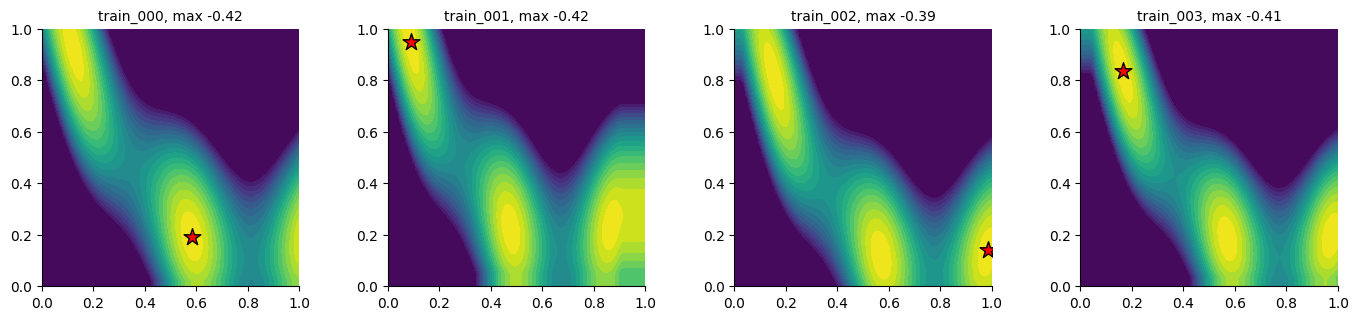

In [2]:
split = load_family_split("../configs/family_splits/branin_split.json")
train_specs = build_specs(split.base_name, split.train_variants, "train")
test_specs = build_specs(split.base_name, split.test_variants, "test")
print(len(train_specs), "training tasks,", len(test_specs), "test tasks")

side = np.linspace(0.0, 1.0, 80)
gx, gy = np.meshgrid(side, side)
pts = np.column_stack([gx.ravel(), gy.ravel()])
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, spec in zip(axes, train_specs[:4]):
    z = spec.objective(pts).reshape(gx.shape)
    ax.contourf(gx, gy, np.maximum(z, -40), 25, cmap="viridis")
    best = pts[np.argmax(z)]
    ax.scatter(*best, marker="*", s=160, c="red", edgecolors="k"); ax.set_title(f"{spec.name}, max {spec.optimum:.2f}", fontsize=10); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

The same landscape, moved around and rescaled. The red star marks each task's best value on the grid (the plots clip values below -40 for readability).

## 2. TAF: borrow the old surrogates

`run_bo_taf` takes the directory of a saved run (here the 12 training tasks: one fitted GP and its data per task, `meta-bo-training/taf-gps/branin_train_v1`) and uses them to build the acquisition function. In the first 3 steps it uses only the old GPs (`source_only_warmup_iters`), so it can propose a point **before it has evaluated anything on the new task**. We compare two ways of weighting the sources, `taf_m` (by similarity of task descriptors) and `taf_r` (by how well each old GP ranks the points evaluated on the new task), with ordinary BO (5 random starts) and random search, on the 3 test tasks with 3 seeds each, 30 evaluations. This cell takes about a minute and a half.

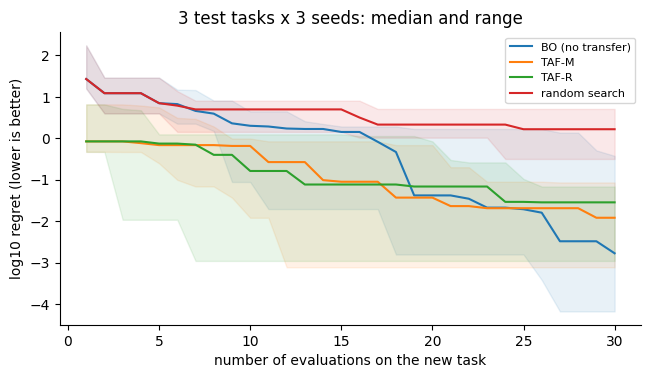

method                  @1      @3      @5     @10     @20     @30   (median log10 regret)
BO (no transfer)      1.43    1.09    0.85    0.30   -1.38   -2.78
TAF-M                -0.07   -0.07   -0.16   -0.18   -1.43   -1.92
TAF-R                -0.07   -0.07   -0.13   -0.79   -1.16   -1.55
random search         1.43    1.09    0.85    0.70    0.33    0.22
first evaluation where the median of ordinary BO is below the median of TAF-M / TAF-R: {'TAF-M': 25, 'TAF-R': 19}


In [3]:
run_dir = "../meta-bo-training/taf-gps/branin_train_v1"
methods = ["BO (no transfer)", "TAF-M", "TAF-R", "random search"]
curves = {m: [] for m in methods}
for spec in test_specs:
    for seed in range(3):
        r = run_bo_scratch(spec.objective, spec.bounds, n_init=5, n_iter=25, seed=seed)
        curves["BO (no transfer)"].append(log_regret(r.y_obs, spec.optimum))
        for name, mode in (("TAF-M", "taf_m"), ("TAF-R", "taf_r")):
            r = run_bo_taf(spec.objective, spec.bounds, taf_run_dir=run_dir, n_init=0, n_iter=30, taf_weight_mode=mode, seed=seed)
            curves[name].append(log_regret(r.y_obs, spec.optimum))
        curves["random search"].append(log_regret(spec.objective(np.random.default_rng(seed).random((30, 2))), spec.optimum))

evals = np.arange(1, 31)
plt.figure(figsize=(7.5, 3.8))
for (name, c), col in zip(curves.items(), ("C0", "C1", "C2", "C3")):
    arr = np.array(c)
    plt.plot(evals, np.median(arr, 0), color=col, label=name); plt.fill_between(evals, arr.min(0), arr.max(0), color=col, alpha=0.1)
plt.xlabel("number of evaluations on the new task"); plt.ylabel("log10 regret (lower is better)")
plt.title("3 test tasks x 3 seeds: median and range"); plt.legend(fontsize=8); plt.show()

print(f"{'method':18s}" + "".join(f"{'@' + str(k):>8s}" for k in (1, 3, 5, 10, 20, 30)) + "   (median log10 regret)")
for name, c in curves.items():
    a = np.array(c); print(f"{name:18s}" + "".join(f"{np.median(a[:, k - 1]):8.2f}" for k in (1, 3, 5, 10, 20, 30)))
first_bo_wins = {n: int(np.argmax(np.median(np.array(curves['BO (no transfer)']), 0) < np.median(np.array(curves[n]), 0))) + 1 for n in ("TAF-M", "TAF-R")}
print("first evaluation where the median of ordinary BO is below the median of TAF-M / TAF-R:", first_bo_wins)

What the plot and the table say (everything is seeded, so you get exactly these numbers):

- **The head start is large.** TAF proposes its first point from the 12 old tasks alone. After the very first evaluation its median log10 regret is -0.07 (a gap of about 0.85), against 1.43 (about 27) for ordinary BO and for random search, which know nothing yet.
- **TAF stays ahead through the first 10 evaluations or so:** at 10 evaluations the medians are -0.18 (TAF-M) and -0.79 (TAF-R) against 0.30 for ordinary BO.
- **Ordinary BO then catches up and overtakes.** Its median falls below TAF-R's from evaluation 19 and below TAF-M's from evaluation 25, and at 30 evaluations it is at -2.78 against -1.92 and -1.55. The repository notes a reason: in OpenBO's TAF the pull of the old tasks does not fade as the new task's own GP becomes confident, so it keeps proposing points where the old tasks improved (see the TAF notes in `CLAUDE.md`).
- **Caveat.** This is 9 runs per method (3 tasks, 3 seeds) and the shaded ranges overlap a lot: the early advantage is clear, the late ranking is not firmly established.

## 3. ConBO: a population model that keeps learning

ConBO targets a *sequence* of users, each of whom arrives, is optimized for 30 evaluations, and leaves. It keeps a Bayesian neural network (with dropout, so that it also gives uncertainty) trained on everybody who came before. For a new user it uses that network's prediction as a stand-in for the unknown objective at first, and hands over to the user's own GP as data accumulates (`α₁ = 5`, `α₂ = 0.2`: full weight on the population model for the first 5 evaluations, then fading to zero at 10). After the user finishes, their data are added to the population.

One run is a whole sequence of 15 users and takes about 20 minutes per seed in the archived benchmark, so we read the archived results (`benchmark_results/conbo_branin_5seeds`: 5 seeds, 5 methods, users 4 to 15, the same simulated Branin users for every method) instead of rerunning. The two lines below are what a run looks like in code, for reference (they are not executed here):

```python
from openbo.optimizers.conbo import ConBOConfig, ConBOPopulation, run_conbo_sequence
# uv run python scripts/run_conbo_benchmark.py --method conbo --test branin --seed 0   # the benchmark script
```

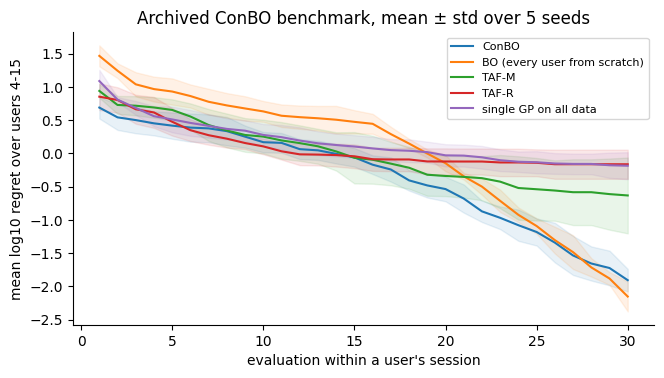

method                              @1      @5     @10     @20     @30
ConBO                             0.69    0.42    0.17   -0.54   -1.91
BO (every user from scratch)      1.46    0.93    0.63   -0.15   -2.15
TAF-M                             0.94    0.65    0.25   -0.34   -0.63
TAF-R                             0.85    0.47    0.10   -0.12   -0.16
single GP on all data             1.09    0.51    0.28   -0.03   -0.19


In [4]:
archive = Path("../benchmark_results/conbo_branin_5seeds/trajectories")
labels = {"conbo": "ConBO", "bo": "BO (every user from scratch)", "taf_m": "TAF-M", "taf_r": "TAF-R", "single_gp": "single GP on all data"}
conbo_curves = {}
for key in labels:
    per_seed = []
    for seed in range(5):
        users = json.loads((archive / f"t1_{key}_branin_s{seed}.json").read_text())["users"][3:]      # users 4-15, as in the archive README
        per_seed.append(np.mean([log_regret(u["y"], u["optimum"]) for u in users], axis=0))
    conbo_curves[key] = np.array(per_seed)                                                           # (seeds, evaluations)

plt.figure(figsize=(7.5, 3.8))
for (key, name), col in zip(labels.items(), ("C0", "C1", "C2", "C3", "C4")):
    arr = conbo_curves[key]; x = np.arange(1, arr.shape[1] + 1)
    plt.plot(x, arr.mean(0), color=col, label=name); plt.fill_between(x, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=col, alpha=0.1)
plt.xlabel("evaluation within a user's session"); plt.ylabel("mean log10 regret over users 4-15")
plt.title("Archived ConBO benchmark, mean ± std over 5 seeds"); plt.legend(fontsize=8); plt.show()

print(f"{'method':30s}" + "".join(f"{'@' + str(k):>8s}" for k in (1, 5, 10, 20, 30)))
for key, name in labels.items():
    arr = conbo_curves[key]; print(f"{name:30s}" + "".join(f"{arr[:, k - 1].mean():8.2f}" for k in (1, 5, 10, 20, 30)))

What the archive shows (5 seeds; the numbers are in the table above):

- **ConBO starts best.** At the first evaluation its mean log10 regret is 0.69 against 1.46 for standard BO, and it stays ahead of standard BO until evaluation 27 (0.42 against 0.93 at evaluation 5, 0.17 against 0.63 at 10). TAF-R is on par with it, or slightly better, in the middle of a session (0.10 at evaluation 10).
- **Standard BO is better at the end:** -2.15 at evaluation 30 against ConBO's -1.91, although the bands (one standard deviation across seeds) overlap, and ConBO is ahead of it in only 2 of the 5 seeds.
- **Read the standard BO curve with care.** In this benchmark every user starts with 16 random evaluations (the setting of the paper's first experiment), so its curve only drops after evaluation 16. ConBO's random starts shrink as the population grows (16, 11, 6, 1, then 0 for the later users), so the two do not start from the same position.
- **TAF-M, TAF-R and the single GP stall** (-0.63, -0.16 and -0.19 at evaluation 30): the pull of the earlier data does not fade.
- The archive uses OpenBO's default handover schedule (`α₁ = 5`, `α₂ = 0.2`); `docs/plans/conbo.md` records what is and is not reproduced from the paper.

## 4. NAF: learn the acquisition function

NAF replaces the hand-designed acquisition function (EI, UCB, ...) with a small neural network: for every candidate point it reads the GP's posterior mean and standard deviation, the point's location, the number of evaluations so far `t` and the budget `T`, and outputs a score; the next point is the one with the highest score. The network is trained with reinforcement learning (PPO) to maximize the reward `-log10(regret)` over many tasks of the family. After training, it needs no old data at all: what it learned lives in the weights. (Training takes hours; OpenBO ships a trained model for this Branin family in `benchmark_results/naf_branin/`.)

First, use the trained model on a new task, like any other optimizer (an ask/tell object, `NAFSequentialOptimizer`; `run_naf` runs the loop).

evaluations: 30 | best value 0.99 | optimum 1.006
first three points:
 [[1.    0.   ]
 [0.904 0.   ]
 [1.    0.196]]
distinct points among the 30: 28


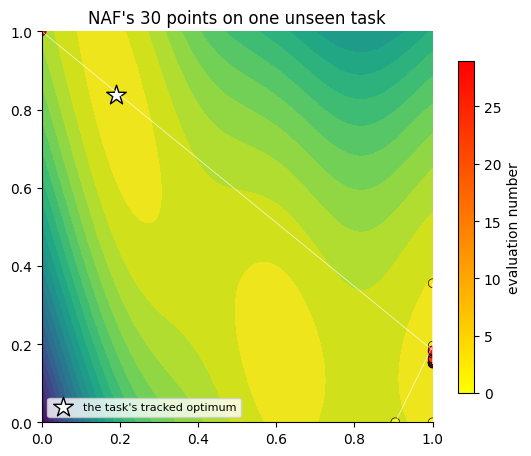

In [5]:
from openbo.optimizers.naf import NAFSequentialOptimizer, run_naf
from openbo.benchmarks.naf_runner import naf_test_tasks, run_naf_method

af_dir = "../benchmark_results/naf_branin/training/branin_metabo50_v1"
task = naf_test_tasks("branin", n_tasks=1, seed=100)[0]            # an unseen shifted and scaled Branin task
x_run, y_run = run_naf(task, NAFSequentialOptimizer.from_directory(af_dir))
print("evaluations:", len(y_run), "| best value", round(float(y_run.max()), 3), "| optimum", round(task.optimum, 3))
print("first three points:\n", np.round(x_run[:3], 3))
print("distinct points among the 30:", len({tuple(np.round(p, 6)) for p in x_run}))

z = task(pts).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.contourf(gx, gy, z, 25, cmap="viridis")
ax.plot(x_run[:, 0], x_run[:, 1], "-", c="white", lw=0.6, alpha=0.7)
sc = ax.scatter(x_run[:, 0], x_run[:, 1], c=np.arange(len(x_run)), cmap="autumn_r", edgecolors="k", linewidths=0.5, s=40)
ax.scatter(*task.argmax, marker="*", s=220, c="white", edgecolors="k", label="the task's tracked optimum")
plt.colorbar(sc, label="evaluation number", shrink=0.85); ax.legend(loc="lower left", fontsize=8)
ax.set_title("NAF's 30 points on one unseen task"); ax.set_aspect("equal"); plt.tight_layout(); plt.show()

What to notice. The first point is the corner `(1, 0)` and the next two are its neighbours: a *probe*. On all 100 archived test tasks of this family the first point is exactly the same corner; the analysis in `docs/plans/naf.md` reads it as a way of learning how this task is shifted and scaled from the value that comes back. After the probe, 26 of the 30 points are in a narrow strip near the right edge (`x₂` between 0.1 and 0.3). The white star marks the tracked optimum in the upper left (value 1.006), but NAF settles in the lower-right valley, whose best value it finds is 0.99 at `(1.0, 0.16)`: the valleys of this family have almost the same height, so a near-optimal answer need not be at the star.

Now a fair comparison. The archive holds 100 unseen test tasks run with every method (`benchmark_results/naf_branin/`), and, if the optional folder `test_results/` exists in your checkout, a longer-trained model in `test_results/naf/` (2000 training iterations instead of 236), which is then added as a dashed line. We plot the median log10 regret over the 100 tasks, from the archived trajectories.

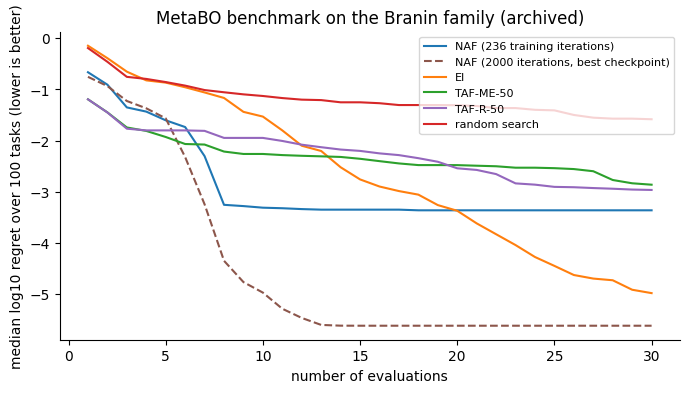

method                                        @1      @5     @10     @20     @30
NAF (236 training iterations)              -0.66   -1.60   -3.31   -3.36   -3.36
NAF (2000 iterations, best checkpoint)     -0.75   -1.57   -4.97   -5.62   -5.62
EI                                         -0.15   -0.87   -1.53   -3.37   -4.98
TAF-ME-50                                  -1.19   -1.93   -2.26   -2.48   -2.86
TAF-R-50                                   -1.19   -1.80   -1.95   -2.54   -2.97
random search                              -0.19   -0.86   -1.13   -1.31   -1.58


In [6]:
def naf_median(path):
    tasks = json.loads(Path(path).read_text())["tasks"]
    return np.median(np.log10(np.maximum(np.array([t["regret"] for t in tasks]), 1e-12)), axis=0)

naf_files = {"NAF (236 training iterations)": "../benchmark_results/naf_branin/trajectories/v1_naf_branin.json"}
longer_run = Path("../test_results/naf/trajectories/v3_2000_naf_branin.json")     # optional: only some checkouts have a test_results/ folder
if longer_run.exists():
    naf_files["NAF (2000 iterations, best checkpoint)"] = str(longer_run)
naf_files.update({
    "EI": "../benchmark_results/naf_branin/trajectories/v1_ei_branin.json",
    "TAF-ME-50": "../benchmark_results/naf_branin/trajectories/v1_taf_me_50_branin.json",
    "TAF-R-50": "../benchmark_results/naf_branin/trajectories/v1_taf_r_50_branin.json",
    "random search": "../benchmark_results/naf_branin/trajectories/v1_random_branin.json",
})
colors = {"NAF (236 training iterations)": "C0", "NAF (2000 iterations, best checkpoint)": "C5", "EI": "C1",
          "TAF-ME-50": "C2", "TAF-R-50": "C4", "random search": "C3"}
naf_curves = {name: naf_median(p) for name, p in naf_files.items()}
plt.figure(figsize=(8, 4))
for name, c in naf_curves.items():
    plt.plot(np.arange(1, 31), c, color=colors[name], label=name, ls="--" if "2000" in name else "-")
plt.xlabel("number of evaluations"); plt.ylabel("median log10 regret over 100 tasks (lower is better)")
plt.title("MetaBO benchmark on the Branin family (archived)"); plt.legend(fontsize=8, loc="upper right"); plt.show()

print(f"{'method':40s}" + "".join(f"{'@' + str(k):>8s}" for k in (1, 5, 10, 20, 30)))
for name, c in naf_curves.items():
    print(f"{name:40s}" + "".join(f"{c[k - 1]:8.2f}" for k in (1, 5, 10, 20, 30)))

What the archived results show:

- **NAF (236 training iterations) is the best method from about evaluation 8 to 15:** -3.31 at 10 evaluations against -1.53 for EI and about -2 for the TAF baselines. It then stops improving: EI catches up around evaluation 20 and is clearly ahead at 30 (-4.98 against -3.36). The repository's analysis is that NAF starts repeating points after about 8 evaluations.
- **The TAF baselines start best** (-1.19 at the first evaluation, because their first point comes from the old tasks) but improve slowly.
- **The model trained for 2000 iterations** (the dashed line, drawn only when that optional file exists) reaches -4.97 at 10 evaluations and -5.62 from evaluation 15 on, ahead of every other method from evaluation 10. Be careful with that line: it is the best checkpoint of **one** training run, chosen by its training reward. The model of the run's last iteration is worse (median -4.88 at 30 evaluations, slightly behind EI; see README section 13), so this is the best case of that run. The flat part at -5.62 is also the resolution limit of the candidate set the policy chooses from (the best regret reachable from it is about -5.56), not a limit of the policy.
- All NAF numbers come from one training run each, and NAF is tied to the family it was trained on.

## Takeaways

- Meta-BO helps when **new tasks resemble old ones**. All three methods start far ahead of ordinary BO in the first evaluations; the price is that you need a family of earlier tasks, and the benefit can disappear (or turn negative) if the new task is not like them.
- The methods differ in *what* they reuse and what that costs: TAF keeps one GP per old task (cheap to build, slow to evaluate as the number of tasks grows, and its pull towards old tasks can slow convergence later); ConBO keeps one network and keeps learning but needs long runs; NAF needs hours of reinforcement-learning training and then costs almost nothing at test time, but is tied to the family it was trained on.
- Compare methods over **many tasks and seeds**, and read single curves with suspicion. Everything in this notebook is a small experiment (and the NAF models are from a single training run each).

**Next steps in the repository:** the README (sections 9 to 11) has the full user guides, benchmark commands and servers for ConBO, TAF+ (a TAF variant with several objectives) and NAF; `docs/plans/` records the design decisions and open questions of each method.